In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix
)

In [2]:
np.random.seed(42)

n = 2000

df = pd.DataFrame({
    "timestamp": pd.date_range(
        "2026-01-01", periods=n, freq="10min"
    ),
    "source_ip": [
        f"192.168.1.{np.random.randint(1, 255)}"
        for _ in range(n)
    ],
    "event_type": np.random.choice(
        ["DATA", "LOGIN", "ROUTING", "FLOOD", "ACCESS"],
        n
    ),
    "protocol": np.random.choice(
        ["TCP", "UDP", "MQTT"], n
    ),
    "packet_size": np.random.randint(50, 1500, n),
    "packet_count": np.random.randint(1, 100, n)
})

df["label"] = (
    (df["event_type"] == "FLOOD") |
    (df["packet_count"] > 85) |
    ((df["packet_size"] > 1300) &
     (df["event_type"] == "ACCESS"))
).astype(int)

print(df.head())
print(df["label"].value_counts())

            timestamp      source_ip event_type protocol  packet_size  \
0 2026-01-01 00:00:00  192.168.1.103       DATA      TCP          300   
1 2026-01-01 00:10:00  192.168.1.180      FLOOD     MQTT         1306   
2 2026-01-01 00:20:00   192.168.1.93    ROUTING      UDP          890   
3 2026-01-01 00:30:00   192.168.1.15      LOGIN      UDP          763   
4 2026-01-01 00:40:00  192.168.1.107       DATA     MQTT         1156   

   packet_count  label  
0            77      0  
1            87      1  
2            73      0  
3            81      0  
4            66      0  
label
0    1312
1     688
Name: count, dtype: int64


In [3]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

df["hour"] = df["timestamp"].dt.hour
df["day"] = df["timestamp"].dt.dayofweek

df["ip_last_octet"] = df["source_ip"].apply(
    lambda x: int(x.split(".")[-1])
)

df = df.drop(["timestamp", "source_ip"], axis=1)

df = pd.get_dummies(
    df,
    columns=["event_type", "protocol"],
    dtype=int
)

print(df.head())

   packet_size  packet_count  label  hour  day  ip_last_octet  \
0          300            77      0     0    3            103   
1         1306            87      1     0    3            180   
2          890            73      0     0    3             93   
3          763            81      0     0    3             15   
4         1156            66      0     0    3            107   

   event_type_ACCESS  event_type_DATA  event_type_FLOOD  event_type_LOGIN  \
0                  0                1                 0                 0   
1                  0                0                 1                 0   
2                  0                0                 0                 0   
3                  0                0                 0                 1   
4                  0                1                 0                 0   

   event_type_ROUTING  protocol_MQTT  protocol_TCP  protocol_UDP  
0                   0              0             1             0  
1           

In [4]:
X = df.drop("label", axis=1)
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [5]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [6]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       262
           1       1.00      1.00      1.00       138

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



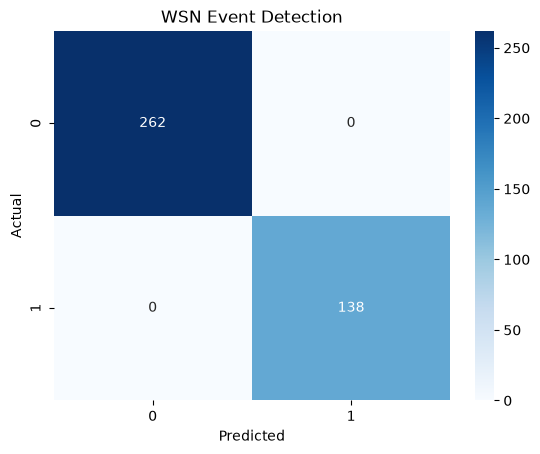

In [7]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("WSN Event Detection")
plt.show()

In [8]:
def predict_event(timestamp, source_ip, event_type,
                  protocol, packet_size, packet_count):

    hour = pd.to_datetime(timestamp).hour
    day = pd.to_datetime(timestamp).dayofweek
    ip_last_octet = int(source_ip.split(".")[-1])

    sample = pd.DataFrame([{
        "hour": hour,
        "day": day,
        "ip_last_octet": ip_last_octet,
        "packet_size": packet_size,
        "packet_count": packet_count,
        "event_type": event_type,
        "protocol": protocol
    }])

    sample = pd.get_dummies(
        sample,
        columns=["event_type", "protocol"],
        dtype=int
    )

    sample = sample.reindex(columns=X.columns, fill_value=0)

    prediction = model.predict(sample)[0]

    if prediction == 1:
        print("Potentially Malicious Network Event")
    else:
        print("Normal Network Event")

In [9]:
predict_event(
    timestamp="2026-01-01 23:30:00",
    source_ip="192.168.1.45",
    event_type="FLOOD",
    protocol="UDP",
    packet_size=1400,
    packet_count=95
)

Potentially Malicious Network Event
